# Неделя 15. Метрики, кросс-валидация и переобучение: как не обмануть себя

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** рассчитать метрики вручную, оценить редкий класс, выбрать threshold по out-of-fold predictions, увидеть overfitting и различить обычную, групповую и временную проверку.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_15_evaluation_cv'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'imbalanced_synthetic.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (750, 8), 'sealed_test': (250, 8)}


,x0,x1,x2,x3,x4,x5,x6,x7
sample_id,,,,,,,,
553,-2.404455,0.451711,-2.089197,0.158444,2.417750,0.778916,0.327872,-0.805614
381,-1.292500,-0.015646,-0.460701,0.040122,1.125180,0.064054,0.111326,1.184415
650,-1.469629,0.833502,-1.525957,0.656379,1.634163,0.785524,0.578192,0.524200


## 1. EDA: редкий положительный класс

Это синтетические данные, а не банковские или медицинские наблюдения.
Положительный класс встречается примерно в 12% строк; label noise немного
меняет долю. Сначала фиксируем задачу: важен поиск редкого класса, основной
критерий подбора — average precision (AP).


,count,mean,std,min,25%,50%,75%,max
x0,750.0,-0.996,1.084,-3.688,-1.651,-1.036,-0.391,3.889
x1,750.0,-0.016,1.470,-4.578,-1.149,0.021,1.109,3.488
x2,750.0,-0.957,1.212,-4.944,-1.685,-1.003,-0.252,2.993
x3,750.0,0.034,1.700,-5.297,-1.113,0.306,1.271,4.130
x4,750.0,1.147,1.630,-5.462,0.320,1.264,2.037,6.331
x5,750.0,0.269,0.651,-2.270,-0.207,0.360,0.760,2.036
x6,750.0,-0.004,1.016,-3.132,-0.696,0.010,0.666,3.093
x7,750.0,0.038,0.970,-3.296,-0.596,0.004,0.715,2.897


,count,fraction
target,,
0,652,0.869333
1,98,0.130667


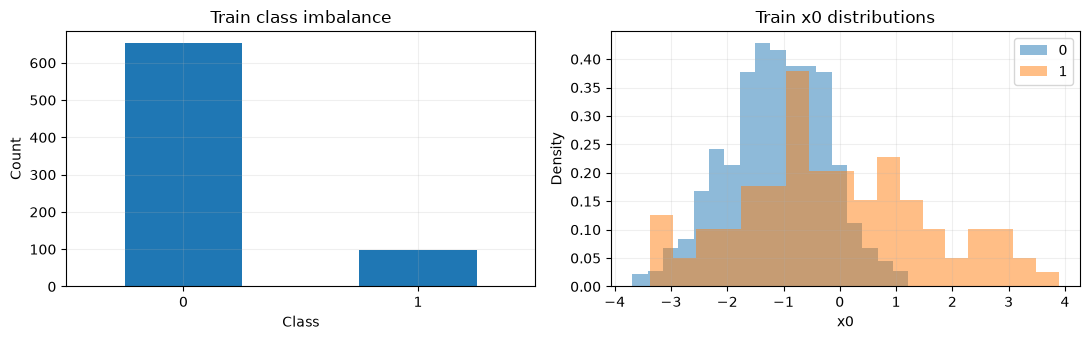

In [3]:
display(X_train.describe().T.round(3))
class_table = y_train.value_counts().sort_index().to_frame("count")
class_table["fraction"] = class_table["count"] / len(y_train)
display(class_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
class_table["count"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Train class imbalance", xlabel="Class", ylabel="Count")
for label in [0, 1]:
    axes[1].hist(X_train.loc[y_train == label, "x0"], bins=18, density=True, alpha=0.5, label=str(label))
axes[1].set(title="Train x0 distributions", xlabel="x0", ylabel="Density")
axes[1].legend(); plt.tight_layout(); plt.show()


## 2. Матрица ошибок и метрики вручную

$$\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN}.$$

Precision отвечает «какая доля сигналов верна», recall — «какая доля настоящих
положительных случаев найдена». Accuracy может быть высокой у модели,
игнорирующей редкий класс. Определим поведение при нулевом знаменателе явно.


In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
example_true = np.array([1, 1, 1, 0, 0, 0, 0, 0])
example_pred = np.array([1, 0, 1, 1, 0, 0, 0, 0])
tn, fp, fn, tp = confusion_matrix(example_true, example_pred, labels=[0, 1]).ravel()
safe_divide = lambda numerator, denominator: numerator/denominator if denominator else 0.0
manual_precision = safe_divide(tp, tp+fp)
manual_recall = safe_divide(tp, tp+fn)
manual_f1 = safe_divide(2*tp, 2*tp+fp+fn)
assert np.isclose(manual_precision, precision_score(example_true, example_pred, zero_division=0))
assert np.isclose(manual_recall, recall_score(example_true, example_pred, zero_division=0))
assert np.isclose(manual_f1, f1_score(example_true, example_pred, zero_division=0))
display(pd.Series({"TN": tn, "FP": fp, "FN": fn, "TP": tp,
                   "precision": manual_precision, "recall": manual_recall, "F1": manual_f1}))


TN           4.000000
FP           1.000000
FN           1.000000
TP           2.000000
precision    0.666667
recall       0.666667
F1           0.666667
dtype: float64

## 3. Регрессия: MAE, RMSE, R²

$$\mathrm{MAE}=\frac1n\sum|y_i-\hat y_i|,\quad
\mathrm{RMSE}=\sqrt{\frac1n\sum(y_i-\hat y_i)^2},\quad
R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$

Квадрат сильнее штрафует крупные ошибки. Ниже маленький **придуманный** пример
используется только для арифметики, не для оценки новой модели. MAPE неудобна,
когда реальные значения близки к нулю; R² не является процентом правильных ответов.


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
observed = np.array([10., 20., 30., 40., 50.])
predicted = np.array([11., 19., 32., 39., 70.])
residual = observed - predicted
manual_mae = np.abs(residual).mean()
manual_rmse = np.sqrt(np.mean(residual**2))
manual_r2 = 1 - np.sum(residual**2) / np.sum((observed-observed.mean())**2)
assert np.isclose(manual_mae, mean_absolute_error(observed, predicted))
assert np.isclose(manual_rmse, np.sqrt(mean_squared_error(observed, predicted)))
assert np.isclose(manual_r2, r2_score(observed, predicted))
display(pd.Series({"MAE": manual_mae, "RMSE": manual_rmse, "R2": manual_r2}))


MAE     5.000000
RMSE    9.022195
R2      0.593000
dtype: float64

## 4. Baseline и честная CV

Сравним константу и логистическую модель на одинаковых folds.
Accuracy, balanced accuracy, AP и log loss описывают разные свойства.
AP суммирует precision с весами прироста recall; это не то же самое, что
trapezoidal area под интерполированной PR-кривой.


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
outer_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1500, random_state=SEED))
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
           "AP": "average_precision", "negative_log_loss": "neg_log_loss"}
comparison = []
for name, model in [("prior baseline", DummyClassifier(strategy="prior")), ("logistic C=1", pipe)]:
    values = cross_validate(model, X_train, y_train, cv=outer_cv, scoring=scoring)
    comparison.append({"model": name, **{metric: values[f"test_{metric}"].mean() for metric in scoring}})
display(pd.DataFrame(comparison).round(3))


,model,accuracy,balanced_accuracy,AP,negative_log_loss
0,prior baseline,0.869,0.500,0.131,-0.388
1,logistic C=1,0.884,0.582,0.437,-0.343


## 5. Переобучение видно по train/validation gap

Строим validation curve дерева на тех же folds. Рост train score вместе
с остановкой CV score — предупреждение о переобучении. Слабые обе оценки
могут указывать на underfitting, но также на слабые признаки или шум меток.
Test пока не участвует даже в графиках.


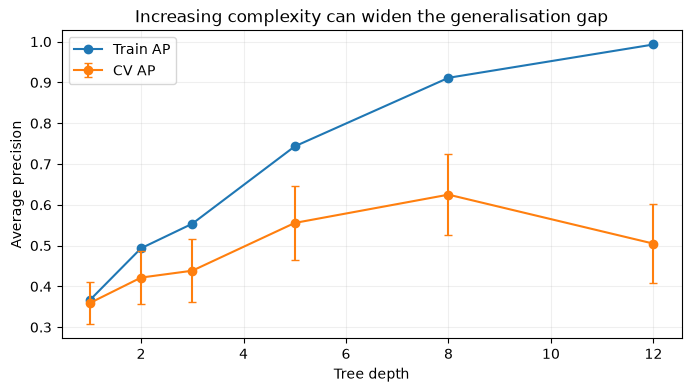

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, learning_curve
depths = [1, 2, 3, 5, 8, 12]
train_scores, valid_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED), X_train, y_train,
    param_name="max_depth", param_range=depths, scoring="average_precision", cv=outer_cv, n_jobs=1)
plt.plot(depths, train_scores.mean(axis=1), "o-", label="Train AP")
plt.errorbar(depths, valid_scores.mean(axis=1), yerr=valid_scores.std(axis=1), fmt="o-", capsize=3, label="CV AP")
plt.xlabel("Tree depth"); plt.ylabel("Average precision"); plt.legend()
plt.title("Increasing complexity can widen the generalisation gap"); plt.show()


## 6. Learning curve: стоит ли собирать больше данных?

Меняем только количество train-строк внутри folds. Это полезный диагноз, но
не прогноз с гарантией: новые данные могут отличаться от текущих. Scaler каждый
раз обучается на доступном обучающем подмножестве.


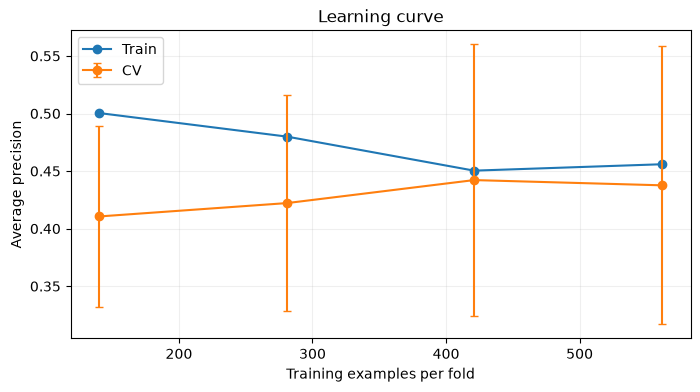

In [8]:
sizes, train_lc, valid_lc = learning_curve(pipe, X_train, y_train,
    train_sizes=[0.25, 0.5, 0.75, 1.0], cv=outer_cv, scoring="average_precision",
    shuffle=True, random_state=SEED, n_jobs=1)
plt.plot(sizes, train_lc.mean(axis=1), "o-", label="Train")
plt.errorbar(sizes, valid_lc.mean(axis=1), yerr=valid_lc.std(axis=1), fmt="o-", label="CV", capsize=3)
plt.xlabel("Training examples per fold"); plt.ylabel("Average precision")
plt.title("Learning curve"); plt.legend(); plt.show()


## 7. OOF-прогнозы с подбором внутри каждого outer fold

Для threshold нужны вероятности объектов, которых модель не видела.
`cross_val_predict(GridSearchCV(...))` выполняет внутренний подбор C только
на outer-train. Так ответ конкретного outer-validation объекта не участвует
ни в fit, ни в выборе C для его прогноза. Это дороже простого CV, но здесь сетка мала.


In [9]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 1)
search = GridSearchCV(pipe, {"logisticregression__C": [0.1, 1.0, 10.0]},
                      scoring="average_precision", cv=inner_cv, n_jobs=1)
oof_probability = cross_val_predict(search, X_train, y_train, cv=outer_cv,
                                     method="predict_proba", n_jobs=1)[:, 1]
assert oof_probability.shape == y_train.shape
assert np.isfinite(oof_probability).all()
print("Каждый train-объект получил один прогноз вне собственного outer-fold обучения.")


Каждый train-объект получил один прогноз вне собственного outer-fold обучения.


## 8. Выбор порога по явно заданной стоимости

Допущение: FN стоит 5, FP — 1 условную единицу. Выберем порог на OOF train.
Стоимость на тех же OOF после выбора порога уже является оценкой для настройки,
а не независимым финальным результатом. После refit вероятности могут немного
сместиться; поэтому threshold также проверяется на итоговом holdout.


Финальные C и threshold: {'logisticregression__C': 10.0} 0.25


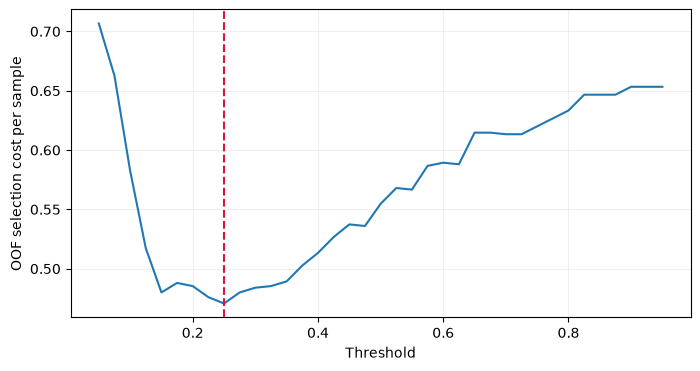

In [10]:
threshold_rows = []
for threshold in np.linspace(0.05, 0.95, 37):
    tn, fp, fn, tp = confusion_matrix(y_train, oof_probability >= threshold, labels=[0, 1]).ravel()
    threshold_rows.append({"threshold": threshold, "cost_per_sample": (fp+5*fn)/len(y_train), "FP": fp, "FN": fn})
threshold_table = pd.DataFrame(threshold_rows)
threshold = float(threshold_table.assign(distance=(threshold_table.threshold-0.5).abs())
                   .sort_values(["cost_per_sample", "distance"]).iloc[0].threshold)
search.fit(X_train, y_train)
print("Финальные C и threshold:", search.best_params_, threshold)
plt.plot(threshold_table.threshold, threshold_table.cost_per_sample)
plt.axvline(threshold, color="crimson", ls="--")
plt.xlabel("Threshold"); plt.ylabel("OOF selection cost per sample"); plt.show()


## 9. Test: метрики порога и метрики вероятностей

ROC AUC и AP вычисляются по вероятностям и не зависят от уже выбранного порога.
F1, recall и стоимость зависят от него. Оба правила (0.5 и OOF threshold)
объявлены до test. После этой ячейки не подбираем новый порог.


In [11]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, log_loss
test_probability = search.predict_proba(X_test)[:, 1]
final_rows = []
for name, cut in [("default 0.5", 0.5), ("OOF cost threshold", threshold)]:
    predicted = test_probability >= cut
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    final_rows.append({"rule": name, "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted), "F1": f1_score(y_test, predicted),
        "accuracy": accuracy_score(y_test, predicted), "cost_per_sample": (fp+5*fn)/len(y_test)})
display(pd.DataFrame(final_rows).round(3))
print({"ROC_AUC": roc_auc_score(y_test, test_probability),
       "AP": average_precision_score(y_test, test_probability),
       "log_loss": log_loss(y_test, test_probability)})


,rule,precision,recall,F1,accuracy,cost_per_sample
0,default 0.5,0.750,0.188,0.300,0.888,0.528
1,OOF cost threshold,0.361,0.406,0.382,0.832,0.472


{'ROC_AUC': 0.7111525229357798, 'AP': 0.3683393794806008, 'log_loss': 0.34419392473227556}


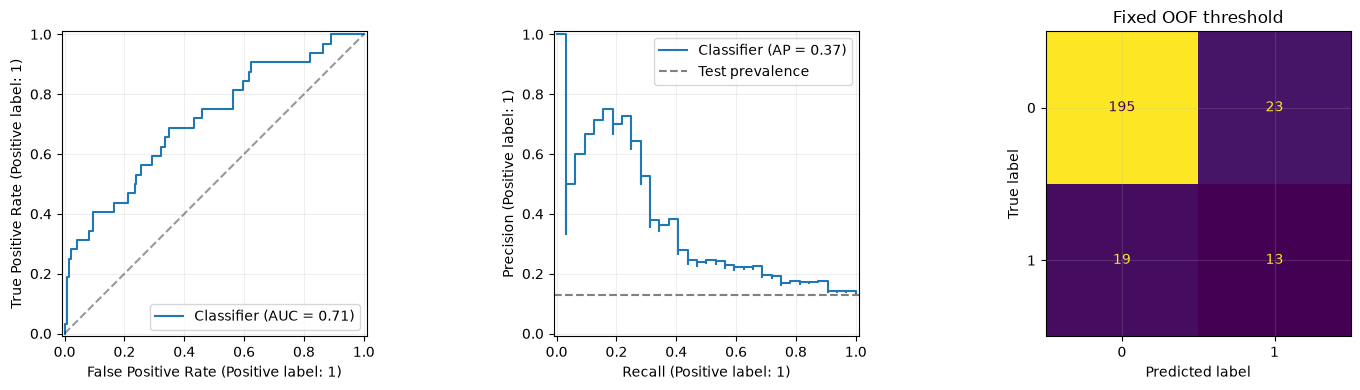

In [12]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1])
axes[1].axhline(y_test.mean(), color="gray", ls="--", label="Test prevalence")
axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test, test_probability >= threshold, ax=axes[2], colorbar=False)
axes[2].set_title("Fixed OOF threshold")
plt.tight_layout(); plt.show()


## 10. Не любой split допустим

Если у одного пользователя несколько строк, random split может поместить его
по обе стороны. `GroupKFold` держит группы раздельно. Для прогноза будущего
обучение должно предшествовать проверке: `TimeSeriesSplit` сохраняет порядок.
Следующие мини-данные синтетические; мы проверяем только индексы split.


In [13]:
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
row_index = np.arange(60)
groups = np.repeat(np.arange(12), 5)
group_cv = GroupKFold(n_splits=3)
for fit_index, val_index in group_cv.split(row_index, groups=groups):
    assert set(groups[fit_index]).isdisjoint(groups[val_index])
time_cv = TimeSeriesSplit(n_splits=3, gap=2)
for fit_index, val_index in time_cv.split(row_index):
    assert fit_index.max() < val_index.min()
    assert val_index.min()-fit_index.max()-1 >= 2
    print("Time split:", (fit_index.min(), fit_index.max()), "→", (val_index.min(), val_index.max()))


Time split: (np.int64(0), np.int64(12)) → (np.int64(15), np.int64(29))
Time split: (np.int64(0), np.int64(27)) → (np.int64(30), np.int64(44))
Time split: (np.int64(0), np.int64(42)) → (np.int64(45), np.int64(59))


## Чек-лист для отчёта о качестве

Назовите единицу наблюдения, момент предсказания, допустимые признаки, split,
baseline, метрику подбора, бюджет поиска и независимый test. Не называйте fold SD
доверительным интервалом. После многократного просмотра test выделите новый
набор для следующего финального подтверждения.

Источники: [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html),
[cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html),
[nested CV example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html),
[common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html).
